In [1]:
# Data manipulation
import numpy as np
import pandas as pd

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset
from sklearn.datasets import fetch_california_housing

# Train-test split
from sklearn.model_selection import train_test_split

# Machine learning model
from sklearn.linear_model import LinearRegression

# Model evaluation
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Display settings
pd.set_option("display.max_columns", None)

# Visualization style
sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
housing = fetch_california_housing(as_frame=True)

df = housing.frame

print("Dataset Loaded Successfully!")

print("Dataset Shape:", df.shape)

display(df.head())

Dataset Loaded Successfully!
Dataset Shape: (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [4]:
print("Dataset Information")
print("===================")

print("\nNumber of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Data Types:")
print(df.dtypes)

print("\nDataset Information:")
df.info()

Dataset Information

Number of Rows: 20640
Number of Columns: 9

Column Names:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']

Dataset Data Types:
MedInc         float64
HouseAge       float64
AveRooms       float64
AveBedrms      float64
Population     float64
AveOccup       float64
Latitude       float64
Longitude      float64
MedHouseVal    float64
dtype: object

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVa

In [5]:
print("Statistical Summary")
print("===================")

display(df.describe().T)

Statistical Summary


,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
HouseAge,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
AveBedrms,20640.0,1.096675,0.473911,0.333333,1.006079,1.048780,1.099526,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
AveOccup,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000
MedHouseVal,20640.0,2.068558,1.153956,0.149990,1.196000,1.797000,2.647250,5.000010


In [6]:
print("Missing Values Analysis")
print("=======================")

missing_values = df.isnull().sum()

missing_percentage = (
    df.isnull().mean() * 100
)

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": missing_percentage
})

display(missing_summary)

Missing Values Analysis


,Missing Values,Missing Percentage
MedInc,0,0.0
HouseAge,0,0.0
AveRooms,0,0.0
AveBedrms,0,0.0
Population,0,0.0
AveOccup,0,0.0
Latitude,0,0.0
Longitude,0,0.0
MedHouseVal,0,0.0


In [7]:
print("Duplicate Records Analysis")
print("==========================")

duplicate_count = df.duplicated().sum()

print("Total Duplicate Rows:", duplicate_count)

print(
    "Duplicate Percentage:",
    round((duplicate_count / len(df)) * 100, 2),
    "%"
)

Duplicate Records Analysis
Total Duplicate Rows: 0
Duplicate Percentage: 0.0 %


In [8]:
print("Unique Values Analysis")
print("======================")

for column in df.columns:
    print(
        f"{column}: {df[column].nunique()} unique values"
    )

Unique Values Analysis
MedInc: 12928 unique values
HouseAge: 52 unique values
AveRooms: 19392 unique values
AveBedrms: 14233 unique values
Population: 3888 unique values
AveOccup: 18841 unique values
Latitude: 862 unique values
Longitude: 844 unique values
MedHouseVal: 3842 unique values


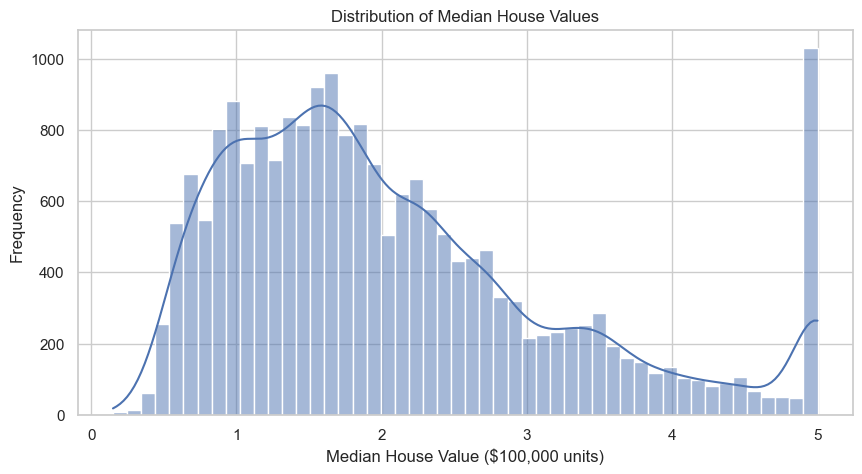

In [9]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="MedHouseVal",
    bins=50,
    kde=True
)

plt.title("Distribution of Median House Values")
plt.xlabel("Median House Value ($100,000 units)")
plt.ylabel("Frequency")

plt.show()

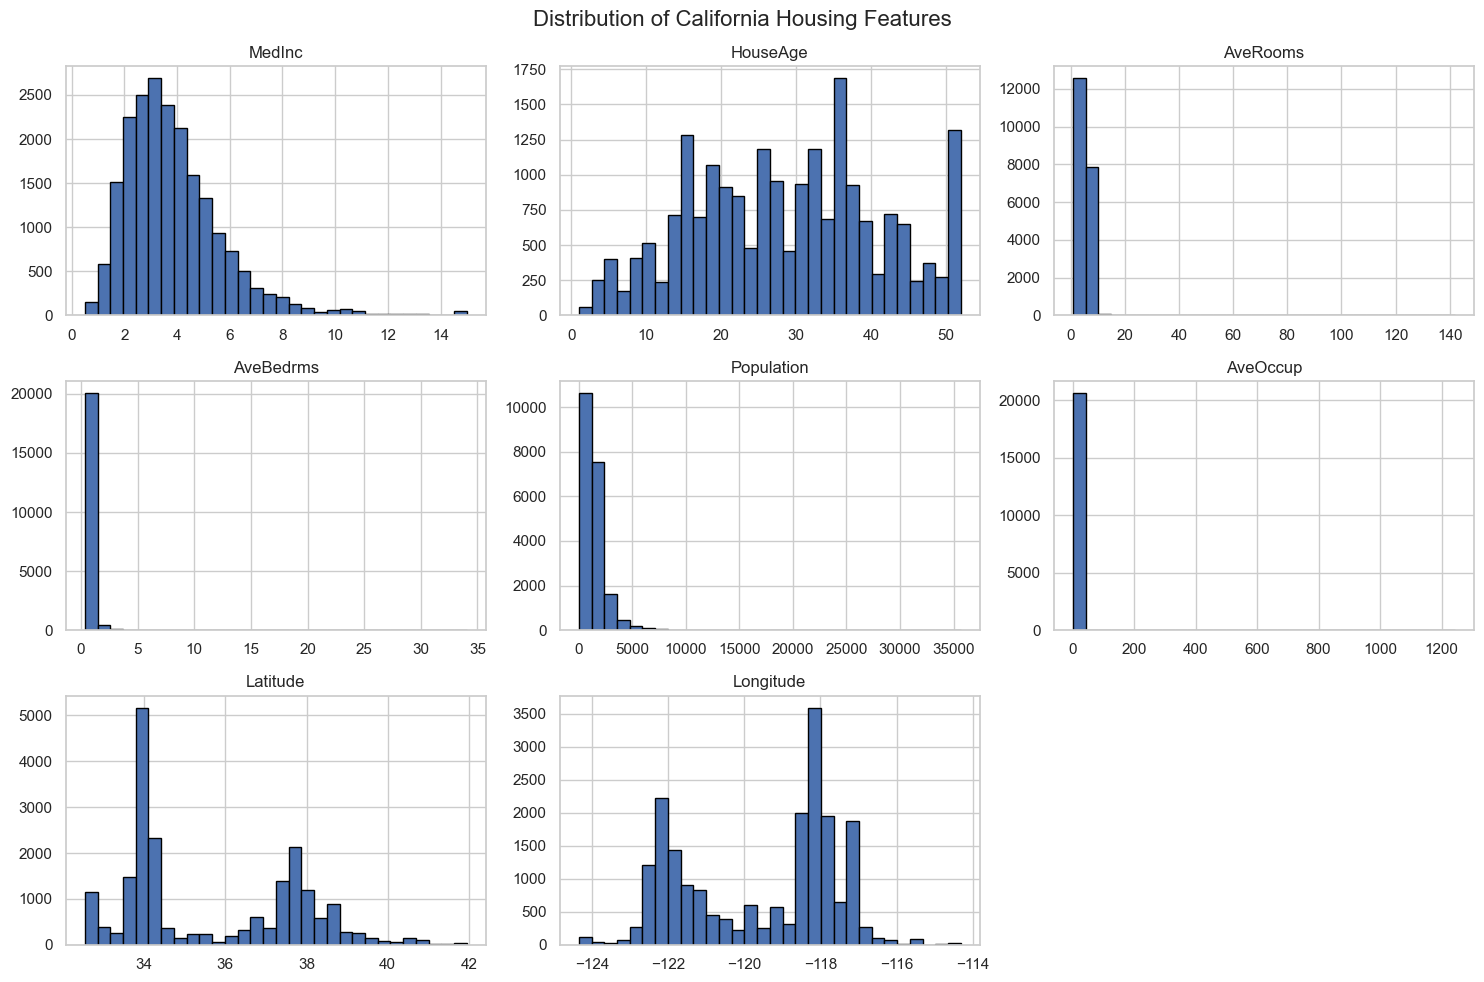

In [10]:
features = housing.feature_names

df[features].hist(
    figsize=(15, 10),
    bins=30,
    edgecolor="black"
)

plt.suptitle(
    "Distribution of California Housing Features",
    fontsize=16
)

plt.tight_layout()
plt.show()

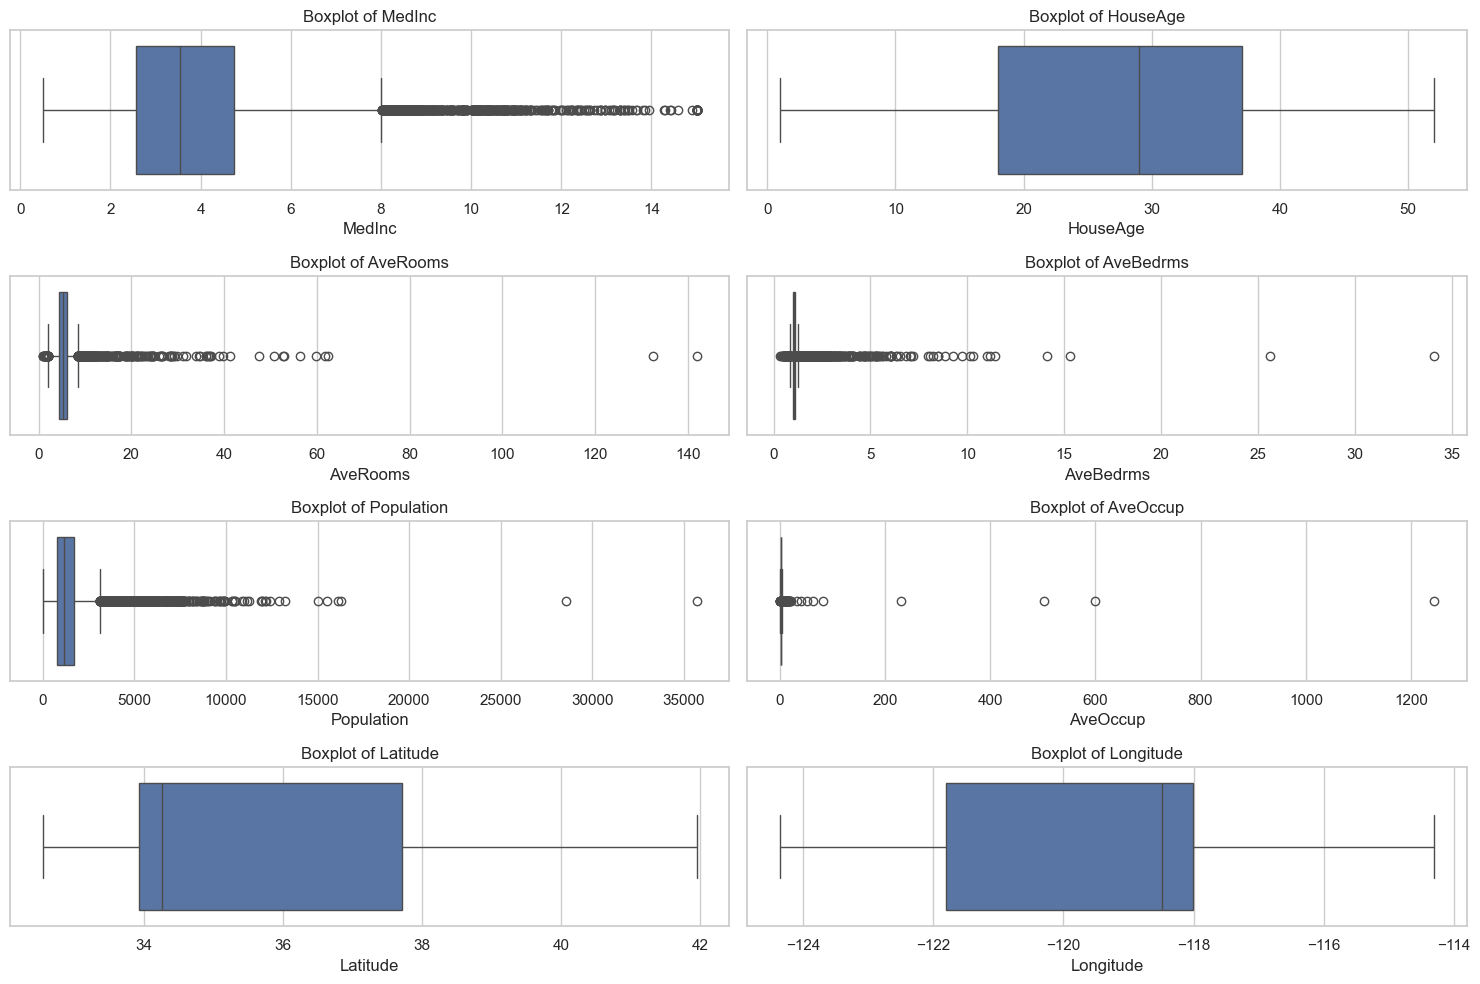

In [11]:
plt.figure(figsize=(15, 10))

for index, column in enumerate(features, 1):

    plt.subplot(4, 2, index)

    sns.boxplot(
        x=df[column]
    )

    plt.title(f"Boxplot of {column}")

plt.tight_layout()
plt.show()

In [12]:
# Independent variables (input features)
X = df[features]

# Dependent variable (target)
y = df["MedHouseVal"]

print("Input Features Shape:", X.shape)
print("Target Variable Shape:", y.shape)

display(X.head())
display(y.head())

Input Features Shape: (20640, 8)
Target Variable Shape: (20640,)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


0    4.526
1    3.585
2    3.521
3    3.413
4    3.422
Name: MedHouseVal, dtype: float64

In [13]:
# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Display dataset sizes
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (16512, 8)
Testing Features: (4128, 8)
Training Target: (16512,)
Testing Target: (4128,)


In [14]:
# Create the Linear Regression model
linear_model = LinearRegression()

# Train the model using training data
linear_model.fit(X_train, y_train)

print("Linear Regression Model Trained Successfully!")

Linear Regression Model Trained Successfully!


In [15]:
# Predict house values using test features
y_pred = linear_model.predict(X_test)

# Display actual and predicted values
comparison = pd.DataFrame({
    "Actual House Value": y_test.values,
    "Predicted House Value": y_pred
})

display(comparison.head(10))

,Actual House Value,Predicted House Value
0,0.47700,0.719123
1,0.45800,1.764017
2,5.00001,2.709659
3,2.18600,2.838926
4,2.78000,2.604657
5,1.58700,2.011754
6,1.98200,2.645500
7,1.57500,2.168755
8,3.40000,2.740746
9,4.46600,3.915615


In [16]:
# Calculate evaluation metrics

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

# Display results
print("Linear Regression Model Evaluation")
print("-----------------------------------")
print("Mean Absolute Error (MAE):", round(mae, 4))
print("Mean Squared Error (MSE):", round(mse, 4))
print("Root Mean Squared Error (RMSE):", round(rmse, 4))
print("R-squared Score (R2):", round(r2, 4))

Linear Regression Model Evaluation
-----------------------------------
Mean Absolute Error (MAE): 0.5332
Mean Squared Error (MSE): 0.5559
Root Mean Squared Error (RMSE): 0.7456
R-squared Score (R2): 0.5758


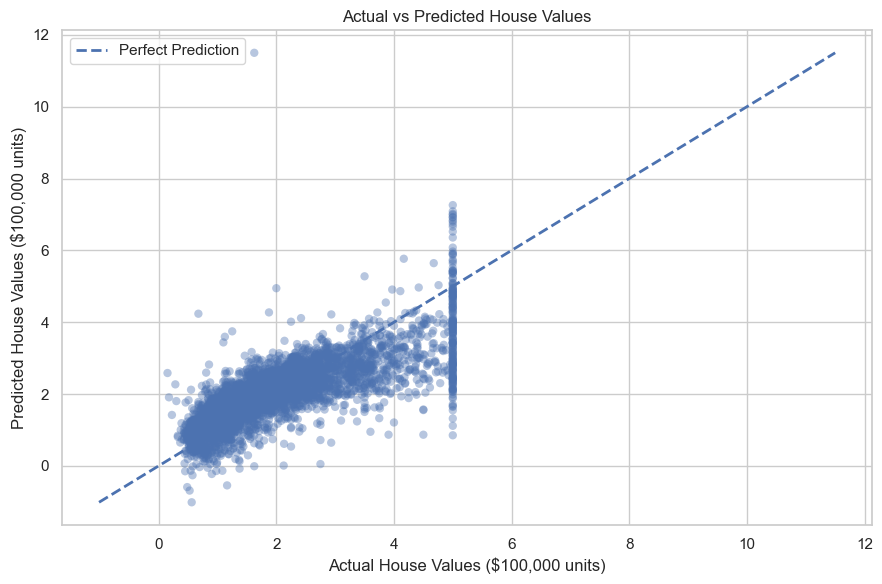

In [17]:
# Actual vs Predicted visualization

plt.figure(figsize=(9, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.4,
    edgecolors="none"
)

# Reference line for perfect predictions
min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--",
    linewidth=2,
    label="Perfect Prediction"
)

plt.title("Actual vs Predicted House Values")
plt.xlabel("Actual House Values ($100,000 units)")
plt.ylabel("Predicted House Values ($100,000 units)")
plt.legend()
plt.tight_layout()
plt.show()

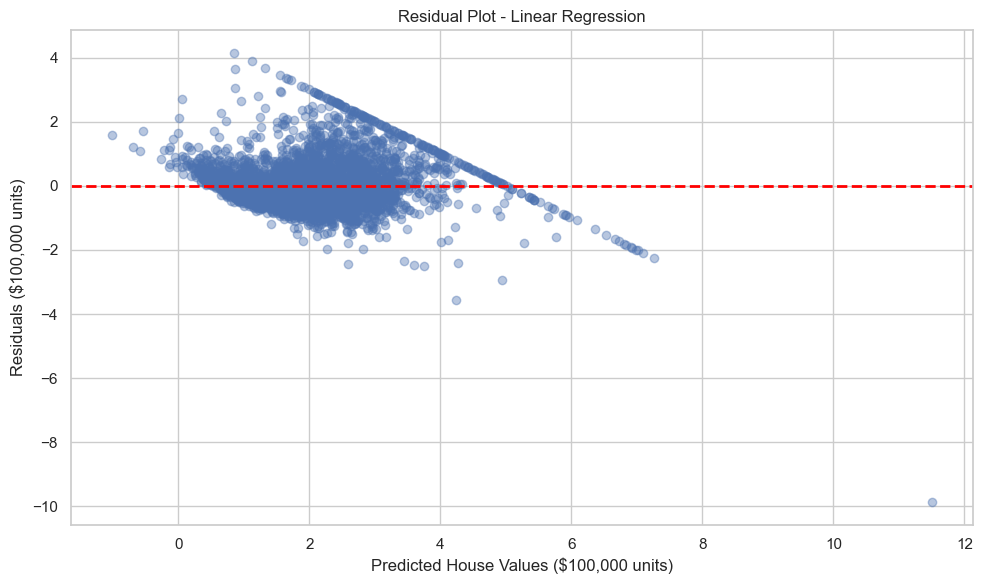

In [18]:
# Calculate residuals
residuals = y_test - y_pred

# Visualize residuals against predicted values
plt.figure(figsize=(10, 6))

plt.scatter(
    y_pred,
    residuals,
    alpha=0.4
)

# Reference line at zero
plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    linewidth=2
)

plt.title("Residual Plot - Linear Regression")
plt.xlabel("Predicted House Values ($100,000 units)")
plt.ylabel("Residuals ($100,000 units)")

plt.tight_layout()
plt.show()

In [19]:
# Extract model coefficients
coefficient_df = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": linear_model.coef_
})

# Sort coefficients
coefficient_df = coefficient_df.sort_values(
    by="Coefficient",
    ascending=False
)

print("Linear Regression Feature Coefficients:")
display(coefficient_df)

# Display intercept
print("Model Intercept:", linear_model.intercept_)

Linear Regression Feature Coefficients:


,Feature,Coefficient
3,AveBedrms,0.783145
0,MedInc,0.448675
1,HouseAge,0.009724
4,Population,-0.000002
5,AveOccup,-0.003526
2,AveRooms,-0.123323
6,Latitude,-0.419792
7,Longitude,-0.433708


Model Intercept: -37.02327770606416


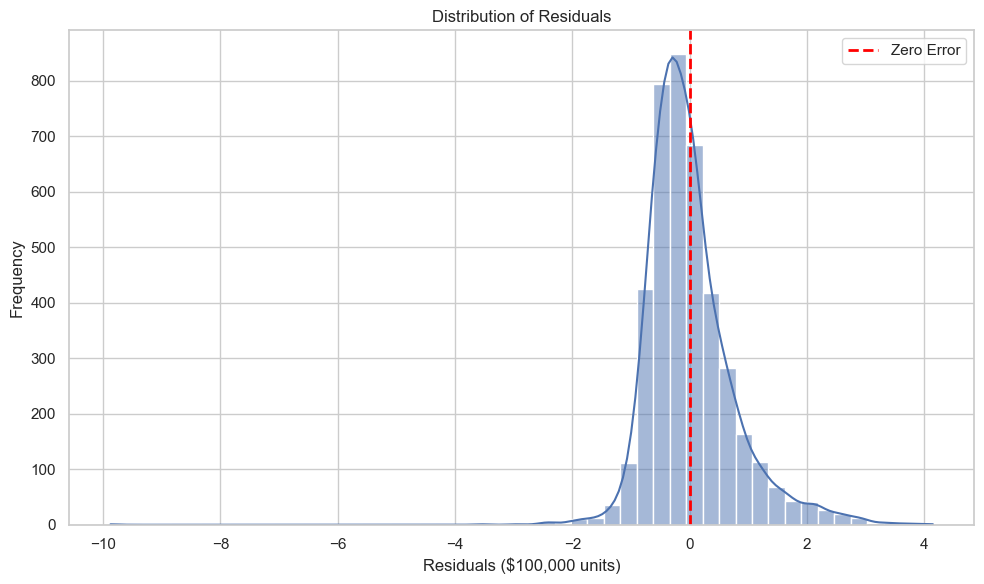

Mean Residual: 0.0035
Residual Standard Deviation: 0.7457


In [20]:
# Visualize residual distribution

plt.figure(figsize=(10, 6))

sns.histplot(
    residuals,
    bins=50,
    kde=True
)

plt.axvline(
    x=0,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Zero Error"
)

plt.title("Distribution of Residuals")
plt.xlabel("Residuals ($100,000 units)")
plt.ylabel("Frequency")

plt.legend()
plt.tight_layout()
plt.show()

print("Mean Residual:", round(residuals.mean(), 4))
print("Residual Standard Deviation:", round(residuals.std(), 4))

In [21]:
# Create a new house observation
new_house = pd.DataFrame({
    "MedInc": [5.0],
    "HouseAge": [25.0],
    "AveRooms": [6.0],
    "AveBedrms": [1.2],
    "Population": [800.0],
    "AveOccup": [3.0],
    "Latitude": [34.05],
    "Longitude": [-118.25]
})

# Predict house value
predicted_value = linear_model.predict(new_house)

# Convert target units into dollars
predicted_dollars = predicted_value[0] * 100000

print("Predicted House Value:", round(predicted_value[0], 3))
print("Estimated House Price: $", round(predicted_dollars, 2))

Predicted House Value: 2.643
Estimated House Price: $ 264287.9


In [22]:
# Create final model performance summary

model_summary = pd.DataFrame({
    "Metric": [
        "MAE",
        "MSE",
        "RMSE",
        "R2 Score"
    ],
    "Value": [
        mae,
        mse,
        rmse,
        r2
    ]
})

display(model_summary)

print("Algorithm: Linear Regression")
print("Dataset: California Housing Dataset")
print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))
print("Number of Features:", X.shape[1])

,Metric,Value
0,MAE,0.533200
1,MSE,0.555892
2,RMSE,0.745581
3,R2 Score,0.575788


Algorithm: Linear Regression
Dataset: California Housing Dataset
Training Samples: 16512
Testing Samples: 4128
Number of Features: 8



# Conclusion — Linear Regression

## 1. Objective
The objective was to predict median house values using the California Housing dataset and Linear Regression.

## 2. Dataset
- Dataset: California Housing Dataset
- Total observations: 20,640
- Input features: 8
- Target variable: MedHouseVal
- Target unit: $100,000

## 3. Workflow Completed
1. Imported required libraries.
2. Loaded and understood the dataset.
3. Performed exploratory data analysis (EDA).
4. Checked missing values and duplicate records.
5. Analyzed distributions, correlations and potential outliers.
6. Separated input features and target variable.
7. Split the dataset into training and testing sets.
8. Trained the Linear Regression model.
9. Generated predictions.
10. Evaluated model performance using MAE, MSE, RMSE and R².
11. Visualized actual versus predicted values.
12. Performed residual analysis.
13. Interpreted model coefficients.
14. Tested the model with a new observation.

## 4. Key Learnings
- Linear Regression models relationships between numerical input features and a continuous target.
- Model performance must be evaluated on unseen test data.
- Residual analysis helps identify prediction patterns and possible model limitations.
- Coefficients explain estimated feature relationships, holding other features constant.

## 5. Limitations
- Linear Regression may not capture complex nonlinear relationships.
- The dataset target is capped at 5.0.
- The model may not accurately predict every geographical area's house values.
- Further validation and feature engineering may improve performance.

## 6. Final Conclusion
Linear Regression provides a useful baseline for predicting house values. Its performance and limitations can be compared with regularized and nonlinear regression algorithms in subsequent practicals.
